# <center><span style="color:red"><u><br/> Analyse économétrique</u></span></center>

## <span style="color:RED">1-Introduction</span>

L'objectif de ce notebook est de conclure notre projet par une analyse économétrique. Nous allons donc effectuer des régressions linéaires ainsi que des tests statistiques afin d'approfondir notre étude des relations entre les différentes variables explicatives et la valeur marchande des joueurs.

Nous étudierons principalement l'influence de **l'âge, de l'âge au carré, du temps de jeu (minutes jouées), des performances offensives (buts et passes décisives) ainsi que du poste occupé par les joueurs**.

Notre variable expliquée sera le **logarithme de la valeur marchande**, et non la valeur marchande directement, car la distribution de cette dernière est fortement asymétrique et présente des valeurs extrêmes. Le logarithme permet ainsi de réduire l'influence de ces valeurs extrêmes et de faciliter l'interprétation des coefficients en termes de variations relatives.

Nous chercherons ainsi à déterminer quelles caractéristiques sont statistiquement associées à la valorisation des joueurs de Premier League lors de la saison 2025-2026.

## <span style="color:RED">1.2-Hypothèses économiques</span>

Pour effectuer notre régression, on peut formuler différentes hypothèses suite à notre analyse descriptive :

- **age** : Relation potentiellement non linéaire
-  **Minutes jouées, Buts, Passes décisives** : Relation positive avec la valeur marchande
-  **Poste** : Différences de valorisation selon les postes, notamment entre gardiens et joueurs de champ

## <span style="color:RED">1.3-Spécification du modèle économétrique</span>


Notre modèle principal peut s'écrire :

$$
\begin{aligned}
\log(V_i) ={}& \beta_0 + \beta_1 Age_i + \beta_2 Age_i^2 \\
&+ \beta_3 Minutes_i + \beta_4 Buts_i \\
&+ \beta_5 Passes_i + \beta_6 Gardien_i + \varepsilon_i
\end{aligned}
$$

Avec :

- $V_i$ : valeur marchande du joueur $i$.
- $\beta_0$ : constante du modèle.
- $\beta_1,\ldots,\beta_5$ : coefficients associés aux variables quantitatives.
- $\beta_6$ : coefficient associé à la variable indicatrice $Gardien_i$.
- $Gardien_i$ : variable binaire valant 1 si le joueur est gardien et 0 s'il est joueur de champ.
- $\varepsilon_i$ : terme d'erreur regroupant les facteurs non observés.

Nous utiliserons la **méthode des moindres carrés ordinaires (MCO)** pour estimer les coefficients.

Il est important de préciser que notre étude est observationnelle : les coefficients représenteront des **associations statistiques**, et non nécessairement des effets causaux.


## <span style="color:red">2- Préparation des variables</span>

### <span style="color:red">2.1- Importation des bibliothèques et des données</span>

In [20]:
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

df_econometrie=pd.read_csv("../../data/processed/dataset_final.csv")

df_econometrie.head()

,id_fbref,joueur,poste,age,annee_naissance,matchs_joues,titularisations,minutes_jouees,buts,passes_decisives,...,cartons_rouges,equivalent_90_minutes,buts_par_90,passes_decisives_par_90,buts_plus_passes_par_90,buts_hors_penalty_par_90,buts_plus_passes_hors_penalty_par_90,nationalite,valeur_marchande,log_valeur_marchande
0,0041f3e6,Mohamadou Kanté,MF,19,2005,11,0,75,0,0,...,0,0.833333,0.000000,0.0,0.000000,0.000000,0.000000,France,1000000,13.815511
1,00963611,Konstantinos Mavropanos,DF,27,1997,31,27,2534,3,0,...,0,28.155556,0.106551,0.0,0.106551,0.106551,0.106551,Greece,18000000,16.705882
2,0107757e,Filip Jørgensen,GK,23,2002,5,3,379,0,0,...,0,4.211111,0.000000,0.0,0.000000,0.000000,0.000000,Denmark,15000000,16.523561
3,013d348e,Melker Ellborg,GK,22,2003,3,3,270,0,0,...,0,3.000000,0.000000,0.0,0.000000,0.000000,0.000000,Sweden,3000000,14.914123
4,01834aa0,Sebastiaan Bornauw,DF,26,1999,12,5,429,0,0,...,0,4.766667,0.000000,0.0,0.000000,0.000000,0.000000,Belgium,8000000,15.894952


### <span style="color:red">2.3- Création de l'âge au carré</span>

Notre modèle utilise la variable explicative âge et son carré pour mettre en avant la potentielle relation non linéaire entre l'âge et la valeur marchande. Nous allons donc créer la variable **âge_carre**.

In [21]:
df_econometrie["age_carre"]=df_econometrie["age"]**2

### <span style="color:red"> 2.4-Création de la variable indicatrice gardien</span>

Notre modèle utilise une variable indicatrice permettant de distinguer les gardiens des autres joueurs afin de mettre en évidence une éventuelle différence de valeur marchande entre les gardiens et les joueurs de champ (défenseurs, milieux et attaquants). Nous allons donc créer cette variable binaire, définie comme suit :

$$
\text{Gardien}_i =
\begin{cases}
1 & \text{si le joueur } i \text{ est gardien,} \\
0 & \text{sinon.}
\end{cases}
$$

In [22]:
df_econometrie["gardien"]=(df_econometrie["poste"].str[:2]=="GK").astype(int)
df_econometrie["gardien"].value_counts()

gardien
0    468
1     37
Name: count, dtype: int64

### <span style="color:red"> 2.5-Sélection des variables explicatives</span>

In [23]:
variables_modele=[
    "log_valeur_marchande",
    "age",
    "age_carre",
    "minutes_jouees",
    "buts",
    "passes_decisives",
    "gardien"
]

df_modele=df_econometrie[variables_modele].copy()

df_modele.head()

,log_valeur_marchande,age,age_carre,minutes_jouees,buts,passes_decisives,gardien
0,13.815511,19,361,75,0,0,0
1,16.705882,27,729,2534,3,0,0
2,16.523561,23,529,379,0,0,1
3,14.914123,22,484,270,0,0,1
4,15.894952,26,676,429,0,0,0


In [24]:
print("Dimensions :",df_modele.shape)
print("Valeurs manquantes :",df_modele.isna().sum().sum())
print("Doublons :",df_modele.index.duplicated().sum())

Dimensions : (505, 7)
Valeurs manquantes : 0
Doublons : 0


## <span style="color:red">3-Estimation des modèles par MCO</span>

## <span style="color:red">3.1-Présentation des modèles</span>

Nous allons partir d'un premier modèle que nous compléterons au fur et à mesure. L'objectif est de commencer par le modèle le plus simple, puis d'ajouter progressivement de nouvelles variables explicatives jusqu'à aboutir à notre modèle principal.

Cette démarche nous permettra d'observer comment l'ajout de nouvelles variables modifie les coefficients estimés, leur significativité statistique ainsi que le pouvoir explicatif du modèle.

*Voici l'ordre des modèles que nous considérerons :*

- **Modèle 1 (M1)** : âge et âge au carré. Nous chercherons à étudier une éventuelle relation non linéaire entre l'âge et la valeur marchande.

- **Modèle 2 (M2)** : M1 + minutes jouées. Nous ajouterons le temps de jeu afin d'étudier son association avec la valeur marchande.

- **Modèle 3 (M3)** : M2 + buts et passes décisives. Nous intégrerons les performances offensives des joueurs.

- **Modèle 4 (M4)** : M3 + variable indicatrice gardien. Nous distinguerons les gardiens des joueurs de champ afin d'étudier les éventuelles différences de valorisation selon cette caractéristique.

Nous comparerons ensuite les résultats obtenus pour ces quatre modèles afin d'identifier les variables statistiquement significatives et d'évaluer leur contribution à l'explication de la valeur marchande des joueurs.

## <span style="color:red">3.2-Modèle 1 </span>


Commençons simplement avec le modèle M1 :
$$
\log(V_i)=\beta_0+\beta_1 Age_i+\beta_2 Age_i^2+\varepsilon_i
$$

L'objectif est de déterminer si la relation potentiellement non linéaire observée dans l'analyse descriptive se retrouve dans notre régression.

In [25]:
modele_1=smf.ols(formula="log_valeur_marchande ~ age + age_carre",data=df_modele).fit(cov_type="HC3")

print(modele_1.summary())

                             OLS Regression Results                             
Dep. Variable:     log_valeur_marchande   R-squared:                       0.361
Model:                              OLS   Adj. R-squared:                  0.359
Method:                   Least Squares   F-statistic:                     78.61
Date:                  Sat, 21 Nov 2026   Prob (F-statistic):           1.99e-30
Time:                          17:54:59   Log-Likelihood:                -730.95
No. Observations:                   505   AIC:                             1468.
Df Residuals:                       502   BIC:                             1481.
Df Model:                             2                                         
Covariance Type:                    HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.5901      1.894

Pour notre premier modèle, nous utilisons la méthode des moindres carrés ordinaires avec des erreurs standards robustes à l'hétéroscédasticité.

Les résultats montrent que les coefficients associés à l'âge (1,4475) et à l'âge au carré (-0,0298) sont statistiquement significatifs au seuil de 5 %.

Le signe positif du coefficient de l'âge et le signe négatif de celui de l'âge au carré suggèrent une relation en U inversé entre l'âge et le logarithme de la valeur marchande. Le maximum estimé se situe autour de 24,3 ans, ce qui est cohérent avec les observations de notre analyse descriptive.

Nous obtenons également un coefficient de détermination de 0,361. Notre modèle explique donc environ 36,1 % de la variabilité du logarithme de la valeur marchande.

Enfin, le modèle est globalement significatif, avec une p-value du test global de 1,99 × 10⁻³⁰.

Ces résultats restent néanmoins à interpréter avec prudence, car notre premier modèle ne tient pas encore compte des autres caractéristiques des joueurs, comme le temps de jeu, les performances offensives ou le poste occupé.

## <span style="color:red">3.3-Modèle 2 </span>


Passons au modèle M2 :
$$
\log(V_i)=\beta_0+\beta_1 Age_i+\beta_2 Age_i^2+\beta_3 Minutes_i + \varepsilon_i
$$

In [26]:
modele_2=smf.ols(formula="log_valeur_marchande ~ age + age_carre + minutes_jouees",data=df_modele).fit(cov_type="HC3")

print(modele_2.summary())

                             OLS Regression Results                             
Dep. Variable:     log_valeur_marchande   R-squared:                       0.571
Model:                              OLS   Adj. R-squared:                  0.568
Method:                   Least Squares   F-statistic:                     178.0
Date:                  Sat, 21 Nov 2026   Prob (F-statistic):           1.47e-78
Time:                          17:54:59   Log-Likelihood:                -630.68
No. Observations:                   505   AIC:                             1269.
Df Residuals:                       501   BIC:                             1286.
Df Model:                             3                                         
Covariance Type:                    HC3                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          4.188

Dans ce deuxième modèle, nous ajoutons les minutes jouées afin d'étudier leur relation avec la valeur marchande des joueurs, une fois l'âge pris en compte.

Tout d'abord, nous observons une amélioration importante du pouvoir explicatif de notre modèle. Le coefficient de détermination \(R^2\) passe de 0,361 dans M1 à 0,571 dans M2. Ainsi, notre deuxième modèle explique environ 57,1 % de la variabilité du logarithme de la valeur marchande.

Concernant les minutes jouées, nous obtenons un coefficient positif, d'environ 0,0006, et statistiquement significatif au seuil de 5 %. Cela suggère que les joueurs disposant d'un temps de jeu plus important tendent à présenter une valeur marchande plus élevée, à âge comparable.

Par ailleurs, les coefficients associés à l'âge (1,0301) et à l'âge au carré (-0,0224) restent statistiquement significatifs. Nous retrouvons donc une relation en U inversé, avec un maximum de valorisation estimé autour de 23 ans.

Enfin, le modèle est globalement significatif, avec une p-value très inférieure à 5 %.

Ces résultats montrent que le temps de jeu apporte une information explicative supplémentaire par rapport à notre premier modèle. Nous allons maintenant chercher à améliorer notre analyse en intégrant les performances offensives des joueurs, notamment les buts et les passes décisives.

## <span style="color:red">3.4-Modèle 3 </span>

Notre troisième modèle s'écrit :
$$
\begin{aligned}
\log(V_i)={}&\beta_0+\beta_1 Age_i+\beta_2 Age_i^2\\
&+\beta_3 Minutes_i+\beta_4 Buts_i\\
&+\beta_5 Passes_i+\varepsilon_i
\end{aligned}
$$

In [27]:
modele_3=smf.ols(
    formula="log_valeur_marchande ~ age + age_carre + minutes_jouees + buts + passes_decisives",
    data=df_modele
).fit(cov_type="HC3")

print(modele_3.summary())

                             OLS Regression Results                             
Dep. Variable:     log_valeur_marchande   R-squared:                       0.599
Model:                              OLS   Adj. R-squared:                  0.595
Method:                   Least Squares   F-statistic:                     129.0
Date:                  Sat, 21 Nov 2026   Prob (F-statistic):           1.56e-87
Time:                          17:54:59   Log-Likelihood:                -613.40
No. Observations:                   505   AIC:                             1239.
Df Residuals:                       499   BIC:                             1264.
Df Model:                             5                                         
Covariance Type:                    HC3                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           

Dans ce troisième modèle, nous ajoutons les buts et les passes décisives afin d'étudier leur relation avec la valeur marchande des joueurs, une fois l'âge et les minutes jouées pris en compte.

Tout d'abord, nous observons une nouvelle amélioration du pouvoir explicatif de notre modèle. Le coefficient de détermination \(R^2\) passe de 0,571 dans M2 à 0,599 dans M3. Notre troisième modèle explique donc environ 59,9 % de la variabilité du logarithme de la valeur marchande.

Concernant les performances offensives, nous obtenons des coefficients positifs et statistiquement significatifs pour les buts (0,0496) et les passes décisives (0,0714). Ainsi, un but supplémentaire est associé à une valeur marchande supérieure d'environ 5,1 %, tandis qu'une passe décisive supplémentaire est associée à une valeur marchande supérieure d'environ 7,4 %, toutes choses égales par ailleurs.

Nous remarquons que le coefficient des passes décisives est supérieur à celui des buts. Cependant, un test statistique sera nécessaire pour déterminer si cette différence est significative.

Par ailleurs, les coefficients associés à l'âge, à son carré et aux minutes jouées restent significatifs. La relation en U inversé entre l'âge et la valeur marchande persiste, avec un maximum estimé autour de 23 ans.

Enfin, notre modèle est globalement significatif, avec une p-value du test global largement inférieure au seuil de 5 %.

Ces résultats suggèrent que les performances offensives apportent une information explicative supplémentaire. Nous allons maintenant compléter notre modèle en intégrant une variable indicatrice permettant de distinguer les gardiens des joueurs de champ.

## <span style="color:red">3.5-Modèle 4 : Modèle principal </span>

Notre modèle final s'écrit :

$$
\begin{aligned}
\log(V_i)={}&\beta_0+\beta_1 Age_i+\beta_2 Age_i^2\\
&+\beta_3 Minutes_i+\beta_4 Buts_i\\
&+\beta_5 Passes_i+\beta_6 Gardien_i+\varepsilon_i
\end{aligned}
$$

Avec :
$$
Gardien_i=
\begin{cases}
1 & \text{si le joueur est gardien}\\
0 & \text{si le joueur est un joueur de champ}
\end{cases}
$$

In [28]:
modele_4=smf.ols(
    formula="log_valeur_marchande ~ age + age_carre + minutes_jouees + buts + passes_decisives + gardien",
    data=df_modele
).fit(cov_type="HC3")

print(modele_4.summary())

                             OLS Regression Results                             
Dep. Variable:     log_valeur_marchande   R-squared:                       0.600
Model:                              OLS   Adj. R-squared:                  0.595
Method:                   Least Squares   F-statistic:                     108.0
Date:                  Sat, 21 Nov 2026   Prob (F-statistic):           7.34e-87
Time:                          17:54:59   Log-Likelihood:                -613.02
No. Observations:                   505   AIC:                             1240.
Df Residuals:                       498   BIC:                             1270.
Df Model:                             6                                         
Covariance Type:                    HC3                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           

Dans ce quatrième modèle, nous ajoutons une variable indicatrice permettant de distinguer les gardiens des joueurs de champ.

Tout d'abord, nous observons que l'ajout de cette variable n'améliore pratiquement pas le pouvoir explicatif de notre modèle. Le coefficient de détermination \(R^2\) passe de 0,599 dans M3 à 0,600 dans M4, tandis que le \(R^2\) ajusté reste quasiment identique, à 0,595.

Concernant la variable `gardien`, nous obtenons un coefficient négatif (-0,1291), ce qui correspond à une valeur marchande estimée environ 12,1 % inférieure pour les gardiens, toutes choses égales par ailleurs. Cependant, ce coefficient n'est pas statistiquement significatif au seuil de 5 %, puisque sa p-value est de 0,336.

Ce résultat est intéressant, car notre analyse descriptive montrait que les gardiens possédaient une valeur marchande médiane nettement inférieure à celle des autres postes. Cependant, cette différence ne semble plus statistiquement significative lorsque nous prenons en compte l'âge, les minutes jouées et les performances offensives.

Par ailleurs, les autres variables explicatives restent statistiquement significatives, notamment l'âge, l'âge au carré, les minutes jouées, les buts et les passes décisives.

Finalement, l'ajout de la variable `gardien` ne semble pas apporter d'information explicative supplémentaire significative. Nous pourrions donc privilégier le modèle M3, plus simple, mais il faudra confirmer ce choix par des tests et des analyses de robustesse.

## <span style="color:red">4-Tests statistiques et diagnostics </span>

### <span style="color:red">4.1-Tests de Wald </span>
Nous allons commencer par tester plusieurs hypothèses sur les coefficients de notre modèle M4.

#### <span style="color:red">A. Test de significativité de la variable gardien </span>

Nous souhaitons déterminer si le statut de gardien apporte une information explicative supplémentaire une fois les autres variables contrôlées.

Les hypothèses sont :
$$
\begin{cases}
H_0 : \beta_6=0\\
H_1 : \beta_6\neq0
\end{cases}
$$

Nous avons déjà observé une p-value de 0,336 pour cette variable. Le test de Wald permettra de formaliser ce résultat.

In [29]:
test_gardien=modele_4.wald_test("gardien=0",scalar=True)

print(test_gardien)

<Wald test (chi2): statistic=0.9265480140008204, p-value=0.33576153087370747, df_denom=1>


Avec une p-value de 0,3358, nous ne rejetons pas H0.

Conclusion : le statut de gardien n'est pas statistiquement significatif dans notre modèle M4, une fois l'âge, le temps de jeu et les performances offensives pris en compte.

#### <span style="color:red">B. Test de significativité conjointe des performances offensives</span>
Dans M4, nous avons observé que les buts et les passes décisives étaient individuellement significatifs.

Mais nous pouvons aussi tester leur significativité conjointe :
$$
\begin{cases}
H_0:\beta_4=\beta_5=0\\
H_1:\text{au moins un des deux coefficients est non nul}
\end{cases}
$$

In [30]:
test_performances=modele_4.wald_test("buts=0,passes_decisives=0",scalar=True)

print(test_performances)

<Wald test (chi2): statistic=48.888123498255226, p-value=2.4214687409268767e-11, df_denom=2>


Nous rejetons donc l'hypothèse nulle.

Conclusion : les buts et les passes décisives sont conjointement significatifs. Ils sont associés à la valeur marchande même après prise en compte des autres variables de M4.

#### <span style="color:red">C. Les passes décisives sont-elles davantage valorisées que les buts ?</span>

Le coefficient des passes décisives est plus élevé, mais cela ne signifie pas nécessairement que la différence est statistiquement significative.

Nous allons donc tester :
$$
\begin{cases}
H_0:\beta_4=\beta_5\\
H_1:\beta_4\neq\beta_5
\end{cases}
$$

In [31]:
test_buts_passes=modele_4.wald_test("buts=passes_decisives",scalar=True)

print(test_buts_passes)

<Wald test (chi2): statistic=0.564228737866357, p-value=0.4525614199293956, df_denom=1>


Nous ne rejetons donc pas l'égalité des deux coefficients.

Conclusion : nous ne disposons pas de preuves statistiques suffisantes pour affirmer que les passes décisives sont davantage associées à la valeur marchande que les buts.

### <span style="color:red">4.3-Analyse des résidus</span>

À la suite de l'estimation de nos quatre modèles et des tests statistiques réalisés, nous avons décidé de retenir **le modèle M3 à ce stade de notre analyse**. En effet, l'ajout de la variable `gardien` dans M4 n'a pas permis d'améliorer significativement notre modèle. Nous privilégions donc M3, qui est plus simple tout en conservant un pouvoir explicatif quasiment identique.

À présent, nous allons étudier les résidus de notre modèle M3 afin de vérifier s'ils présentent des anomalies susceptibles d'affecter notre analyse économétrique.

Pour cela, nous allons représenter les résidus en fonction des valeurs ajustées afin d'observer leur répartition autour de zéro.

Cette analyse nous permettra notamment d'identifier d'éventuels problèmes de spécification, d'hétéroscédasticité ou la présence de valeurs atypiques.

Rappelons que nous utilisons des **erreurs standards robustes HC3**, ce qui permet de rendre nos tests statistiques moins sensibles à une éventuelle hétéroscédasticité. Cependant, cela ne corrige pas les éventuels problèmes de spécification du modèle.

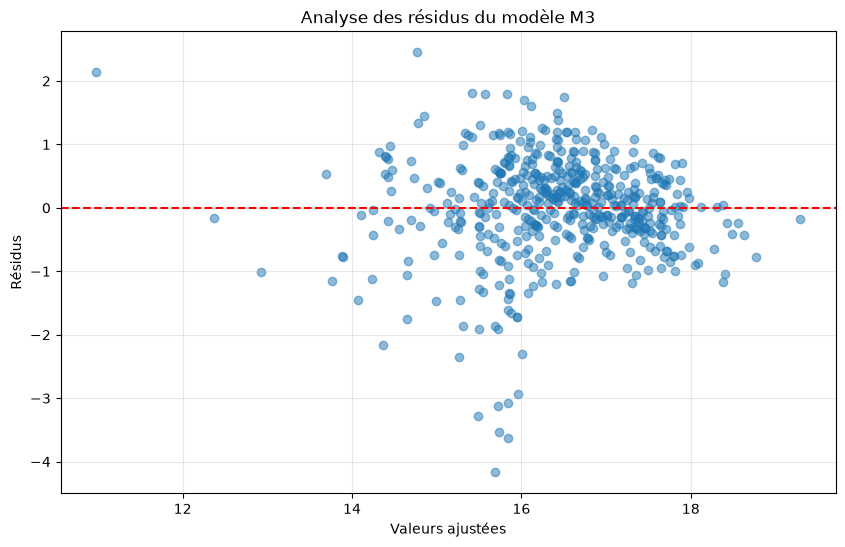

In [32]:
plt.figure(figsize=(10,6))

plt.scatter(modele_3.fittedvalues,modele_3.resid,alpha=0.5)
plt.axhline(0,color="red",linestyle="--")

plt.xlabel("Valeurs ajustées")
plt.ylabel("Résidus")
plt.title("Analyse des résidus du modèle M3")
plt.grid(alpha=0.3)

plt.show()

Le graphique des résidus du modèle M3 montre que ceux-ci sont globalement répartis autour de zéro. Cependant, nous remarquons que leur dispersion semble varier selon les valeurs ajustées, ce qui pourrait suggérer la présence d'hétéroscédasticité.

Nous observons également quelques résidus négatifs particulièrement importants, indiquant que notre modèle surestime la valeur marchande de certains joueurs.

L'utilisation d'erreurs standards robustes HC3 permet de rendre nos tests statistiques moins sensibles à une éventuelle hétéroscédasticité. Néanmoins, cette méthode ne corrige pas les autres problèmes potentiels, comme une mauvaise spécification du modèle ou la présence d'observations influentes.

Ces résultats nous invitent donc à rester prudents dans l'interprétation de nos estimations.

### <span style="color:red">4.4-Analyse de la multicolinéarité</span>
Lors de l'estimation de nos modèles, nous avons observé un *Condition Number* relativement élevé, ce qui pourrait indiquer un problème de multicolinéarité entre certaines variables explicatives.

Nous allons donc calculer les facteurs d'inflation de la variance (VIF) pour les variables de notre modèle M3.

L'objectif est d'identifier les variables fortement liées entre elles, susceptibles de rendre les coefficients estimés moins précis.

Nous porterons notamment une attention particulière à l'âge et à son carré, qui sont naturellement corrélés.

In [33]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X=pd.DataFrame(modele_3.model.exog,columns=modele_3.model.exog_names)

vif=pd.DataFrame({"Variable": X.columns,"VIF":[variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})

vif

,Variable,VIF
0,Intercept,1.000000
1,age,99.134837
2,age_carre,97.716805
3,minutes_jouees,1.526771
4,buts,1.356330
5,passes_decisives,1.395940


L'analyse des VIF nous permet d'étudier les éventuels problèmes de multicolinéarité entre les variables explicatives de notre modèle M3.

Tout d'abord, nous observons des VIF particulièrement élevés pour l'âge (99,13) et son carré (97,72). Cette forte multicolinéarité s'explique principalement par la relation mathématique entre ces deux variables, que nous avons volontairement introduites afin de modéliser une relation quadratique.

Cependant, cela ne signifie pas que notre modèle est invalide. Nous décidons donc de conserver notre spécification initiale, tout en gardant à l'esprit que cette multicolinéarité peut affecter la précision de certaines estimations.

Concernant les autres variables explicatives, nous obtenons des VIF relativement faibles :

- **Minutes jouées :** 1,53.
- **Buts :** 1,36.
- **Passes décisives :** 1,40.

Ces trois valeurs sont proches de 1 et largement inférieures aux seuils habituellement utilisés pour détecter une multicolinéarité problématique. Cela suggère que ces variables apportent des informations suffisamment distinctes et qu'elles ne présentent pas de problème majeur de multicolinéarité dans notre modèle.

Ainsi, **la multicolinéarité observée concerne principalement l'âge et son carré**. Nous pouvons donc conserver l'ensemble de nos variables explicatives pour la suite de notre analyse économétrique, tout en restant prudents dans l'interprétation des coefficients associés à l'âge.

## <span style="color:red">5-Comparaison des modèles</span>

In [34]:
comparaison_modeles=pd.DataFrame({
    "Modèle": ["M1", "M2", "M3", "M4"],
    "Observations": [
        modele_1.nobs,
        modele_2.nobs,
        modele_3.nobs,
        modele_4.nobs
    ],
    "R²": [
        modele_1.rsquared,
        modele_2.rsquared,
        modele_3.rsquared,
        modele_4.rsquared
    ],
    "R² ajusté": [
        modele_1.rsquared_adj,
        modele_2.rsquared_adj,
        modele_3.rsquared_adj,
        modele_4.rsquared_adj
    ],
    "AIC": [
        modele_1.aic,
        modele_2.aic,
        modele_3.aic,
        modele_4.aic
    ],
    "BIC": [
        modele_1.bic,
        modele_2.bic,
        modele_3.bic,
        modele_4.bic
    ]
})

comparaison_modeles.round(3)

,Modèle,Observations,R²,R² ajusté,AIC,BIC
0,M1,505.0,0.361,0.359,1467.891,1480.564
1,M2,505.0,0.571,0.568,1269.353,1286.251
2,M3,505.0,0.599,0.595,1238.798,1264.145
3,M4,505.0,0.600,0.595,1240.046,1269.618


La comparaison des quatre modèles nous permet de conclure que **le modèle M3 semble être le plus pertinent pour expliquer la valeur marchande des joueurs de Premier League**.

En effet, nous observons une amélioration progressive du pouvoir explicatif entre M1 et M3, avec un coefficient de détermination \(R^2\) passant de 0,361 à 0,599. De plus, M3 présente les critères AIC (1239) et BIC (1264) les plus faibles parmi les quatre modèles, ce qui indique un meilleur compromis entre qualité d'ajustement et complexité du modèle.

Bien que M4 présente un \(R^2\) légèrement supérieur (0,600), l'ajout de la variable `gardien` n'améliore pratiquement pas le pouvoir explicatif du modèle. De plus, cette variable n'est pas statistiquement significative au seuil de 5 % (p-value = 0,336), tandis que les autres variables explicatives de M3 restent significatives.

Ainsi, **nous décidons de privilégier le modèle M3**, qui présente un bon pouvoir explicatif tout en étant plus simple et plus parcimonieux que M4. Ce choix reste néanmoins soumis aux analyses de robustesse que nous allons effectuer par la suite.

## <span style="color:red">6-Décomposition de Shapley</span>

In [35]:
from pyshapley2 import shapley2

resultat=shapley2(
    df_modele,
    depvar="log_valeur_marchande",
    indepvars=[
        "age",
        "age_carre",
        "minutes_jouees",
        "buts",
        "passes_decisives"
    ],
    stat="r2",
    groups={
        "Âge": ["age", "age_carre"],
        "Minutes jouées": ["minutes_jouees"],
        "Buts": ["buts"],
        "Passes décisives": ["passes_decisives"]
    }
)

resultat.summary()

Shapley-Owen decomposition  |  depvar: log_valeur_marchande  |  stat: r2  |  command: ols
Observations: 505  |  Subsets: 16  |  K=4

Factor     │ Shapley value │ Per cent  │Shapley value │  Per cent   
           │  (estimate)   │(estimate) │ (normalized) │(normalized) 
───────────┼───────────────┼───────────┼──────────────┼─────────────
Âge        │       0.31323 │    52.30 % │      0.33019 │      55.13 %
Minutes jo │       0.15288 │    25.53 % │      0.16116 │      26.91 %
Buts       │       0.05170 │     8.63 % │      0.05450 │       9.10 %
Passes déc │       0.05036 │     8.41 % │      0.05309 │       8.86 %
───────────┼───────────────┼───────────┼──────────────┼─────────────
Residual   │       0.03077 │     5.14 % │              │             
───────────┼───────────────┼───────────┼──────────────┼─────────────
TOTAL      │       0.59894 │   100.00 % │      0.59894 │     100.00 %
───────────┼───────────────┼───────────┼──────────────┼─────────────

Groups:
  Âge: age, age_carre
  

'Shapley-Owen decomposition  |  depvar: log_valeur_marchande  |  stat: r2  |  command: ols\nObservations: 505  |  Subsets: 16  |  K=4\n\nFactor     │ Shapley value │ Per cent  │Shapley value │  Per cent   \n           │  (estimate)   │(estimate) │ (normalized) │(normalized) \n───────────┼───────────────┼───────────┼──────────────┼─────────────\nÂge        │       0.31323 │    52.30 % │      0.33019 │      55.13 %\nMinutes jo │       0.15288 │    25.53 % │      0.16116 │      26.91 %\nButs       │       0.05170 │     8.63 % │      0.05450 │       9.10 %\nPasses déc │       0.05036 │     8.41 % │      0.05309 │       8.86 %\n───────────┼───────────────┼───────────┼──────────────┼─────────────\nResidual   │       0.03077 │     5.14 % │              │             \n───────────┼───────────────┼───────────┼──────────────┼─────────────\nTOTAL      │       0.59894 │   100.00 % │      0.59894 │     100.00 %\n───────────┼───────────────┼───────────┼──────────────┼─────────────\n\nGroups:\n  Âge:

(<Figure size 900x500 with 1 Axes>,
 <Axes: title={'center': 'Shapley-Owen decomposition | depvar: log_valeur_marchande | stat: r2'}, xlabel='Shapley contribution % (normalised · r2)'>)

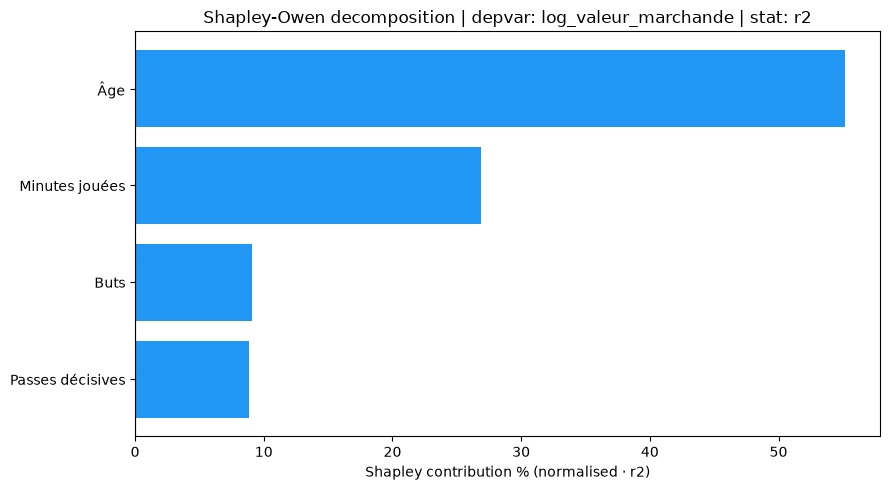

In [36]:
resultat.plot(kind="norm_pct",figsize=(9, 5))

La décomposition de Shapley du coefficient de détermination de notre modèle M3 permet d'identifier la contribution relative de chaque facteur à son pouvoir explicatif.

Nous observons que **l'âge, regroupé avec son carré, constitue le facteur le plus important**, avec environ 55 % du R² expliqué. Les minutes jouées arrivent en deuxième position, avec une contribution d'environ 27 %. Enfin, les buts et les passes décisives présentent des contributions plus faibles, proches de 9 % chacun.

Ces résultats suggèrent que, parmi les variables retenues dans notre modèle, les caractéristiques liées à l'âge et au temps de jeu jouent un rôle prépondérant dans l'explication des différences de valeur marchande entre les joueurs.

Il convient néanmoins de souligner que cette décomposition mesure une contribution au pouvoir explicatif du modèle et non un effet causal. Elle dépend également des variables explicatives retenues dans notre spécification.

## <span style="color:red">7-Conclusion générale du projet</span>
L'objectif de ce projet était de comprendre les principaux facteurs permettant d'expliquer la valeur marchande des joueurs de Premier League lors de la saison 2025-2026, à partir de leurs caractéristiques individuelles et de leurs performances sportives.

Pour répondre à cette problématique, nous avons tout d'abord construit une base de données en combinant les informations issues de Transfermarkt, concernant notamment les valeurs marchandes et les caractéristiques des joueurs, avec les statistiques sportives disponibles sur FBref. Après le nettoyage et la fusion de ces données, nous avons obtenu un échantillon de **505 joueurs**.

Dans un second temps, notre analyse descriptive nous a permis d'identifier plusieurs relations intéressantes. Nous avons notamment observé une relation non linéaire entre l'âge et la valeur marchande, ainsi que des associations positives entre cette dernière, le temps de jeu et les performances offensives des joueurs.

Nous avons ensuite approfondi cette analyse à l'aide de plusieurs modèles de régression linéaire estimés par la méthode des moindres carrés ordinaires (MCO), en utilisant des erreurs standards robustes HC3.

La comparaison de nos quatre modèles nous a conduits à retenir **le modèle M3**, intégrant l'âge, son carré, les minutes jouées, les buts et les passes décisives. Ce modèle présente un coefficient de détermination de **0,599**, ce qui signifie qu'il explique environ **59,9 % de la variabilité du logarithme de la valeur marchande** des joueurs de notre échantillon.

Nos estimations mettent en évidence plusieurs résultats :

- **L'âge entretient une relation en U inversé avec la valeur marchande**, avec un maximum estimé autour de 23 ans, toutes choses égales par ailleurs.
- **Le temps de jeu est positivement associé à la valeur marchande** : les joueurs qui accumulent davantage de minutes présentent généralement des valeurs marchandes plus élevées, à caractéristiques contrôlées identiques.
- **Les buts et les passes décisives présentent également des associations positives et statistiquement significatives**, ce qui confirme l'intérêt des performances offensives dans l'explication de la valeur marchande.

Enfin, la décomposition de Shapley du R² nous a permis d'approfondir notre interprétation. Nous avons observé que **l'âge représente environ 55 % du pouvoir explicatif attribué par la méthode**, suivi des minutes jouées (27 %), puis des buts et des passes décisives (environ 9 % chacun). Ainsi, parmi les facteurs étudiés, l'âge et le temps de jeu occupent une place prépondérante dans l'explication statistique des différences de valeur marchande.


### <span style="color:red">Limites de notre étude</span>
Malgré ces résultats, notre analyse présente certaines limites.

Tout d'abord, notre modèle repose sur un nombre limité de variables explicatives. Or, la valeur marchande d'un joueur dépend également de nombreux facteurs que nous n'avons pas intégrés, comme la durée de son contrat, sa réputation, son potentiel, son historique de blessures ou encore les performances défensives.

De plus, notre étude porte uniquement sur les joueurs de Premier League et sur une seule saison. Nos résultats ne peuvent donc pas nécessairement être généralisés à d'autres championnats ou à d'autres périodes.

Par ailleurs, les valeurs marchandes utilisées sont des estimations issues de Transfermarkt et ne correspondent pas nécessairement aux montants réellement payés lors des transferts.

Enfin, les relations mises en évidence dans notre modèle sont **des associations statistiques et non des relations causales**. Nous ne pouvons donc pas affirmer, par exemple, qu'une augmentation du nombre de buts entraîne directement une hausse de la valeur marchande d'un joueur.

### <span style="color:red">Perspectives d'amélioration</span>
Pour prolonger ce projet, plusieurs pistes pourraient être envisagées.

Nous pourrions notamment enrichir notre base de données avec des variables supplémentaires, intégrer plusieurs saisons et comparer les résultats entre différents championnats européens.

Il serait également intéressant d'estimer des modèles distincts selon les postes, afin de mieux prendre en compte les spécificités des performances attendues pour chaque catégorie de joueurs.

Enfin, une extension intéressante serait de comparer notre modèle MCO à des méthodes de régression pénalisée, notamment Ridge et Lasso. Ces méthodes permettraient de régulariser les coefficients estimés, de limiter certains problèmes liés à la multicolinéarité et, dans le cas du Lasso, de réaliser une sélection de variables.

Nous pourrions alors comparer les performances prédictives de ces différentes méthodes sur un échantillon de test, à l'aide d'indicateurs comme le RMSE, le MAE et le R². Cela nous permettrait de déterminer si des modèles régularisés offrent de meilleures performances prédictives que notre modèle économétrique initial.

À plus long terme, nous pourrions également envisager des méthodes de machine learning non linéaires, comme les forêts aléatoires ou le gradient boosting, afin de prendre en compte des relations plus complexes entre les caractéristiques des joueurs et leur valeur marchande.

### <span style="color:red">Bilan</span>
**Pour conclure, notre étude montre que l'âge, le temps de jeu et les performances offensives constituent des facteurs significativement associés à la valeur marchande des joueurs de Premier League.**

Notre modèle M3 permet d'expliquer une part importante des différences observées entre les joueurs, tout en restant relativement simple et interprétable.

Ce projet nous a ainsi permis de mettre en pratique une démarche complète d'analyse de données et de modélisation économétrique, depuis la collecte des données jusqu'à l'interprétation des résultats, tout en mettant en évidence les possibilités et les limites d'une approche statistique appliquée au football professionnel.